# Data Analytics Approach for Thyroid Disease Detection

## Project Overview
This notebook presents a complete data analytics workflow for thyroid disease detection using a real-world clinical dataset. The analysis combines data cleaning, exploratory data analysis, inferential statistics, interpretable statistical modeling, and machine learning classification.

## Objective of the Study
- To understand the structure and quality of the uploaded thyroid dataset.
- To preprocess the dataset for robust statistical and machine learning analysis.
- To identify important factors associated with thyroid disease.
- To build predictive models that classify whether a patient is likely to have thyroid disease.

## Problem Statement
Thyroid disorders are common endocrine conditions, but their diagnosis may be delayed when multiple clinical indicators must be interpreted together. A data analytics approach can help summarize patient information, detect important patterns, and support early disease screening.

## Scope of the Project
This project focuses on binary disease screening for academic analysis. The original target contains multiple thyroid-related classes, but for the main modeling pipeline the outcome is converted to **Disease vs No Disease**. This improves interpretability and supports a strong final-year project workflow.

## Tools and Libraries Used
Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Statsmodels, and Scikit-learn.

In [1]:
# ==========================================
# 1. Import libraries
# ==========================================
import os
import re
import math
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import shapiro, levene, mannwhitneyu, chi2_contingency, ttest_ind, spearmanr, pearsonr

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif

from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42
OUTPUT_DIR = "thyroid_project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully.")
print(f"Output directory: {OUTPUT_DIR}")

Libraries imported successfully.
Output directory: thyroid_project_outputs


In [2]:
# ==========================================
# 2. Helper functions
# ==========================================
def print_md(text):
    display(Markdown(text))

def safe_savefig(filename):
    """Save figure safely without breaking execution if file saving fails."""
    try:
        plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches="tight")
        print(f"Saved plot: {filename}")
    except Exception as e:
        print(f"Could not save plot {filename}: {e}")

def clean_column_name(col):
    col = str(col).strip().lower()
    col = re.sub(r"[^a-z0-9]+", "_", col)
    col = re.sub(r"_+", "_", col).strip("_")
    return col

def detect_binary_like(series):
    vals = set(str(v).strip().lower() for v in series.dropna().unique())
    binary_sets = [
        {"true", "false"}, {"t", "f"}, {"yes", "no"},
        {"y", "n"}, {"0", "1"}, {"male", "female"}, {"m", "f"}
    ]
    return any(vals.issubset(bset) for bset in binary_sets) and len(vals) <= 2

def normalize_bool_like(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    mapping = {
        "true": 1, "false": 0,
        "t": 1, "f": 0,
        "yes": 1, "no": 0,
        "y": 1, "n": 0,
        "1": 1, "0": 0
    }
    return mapping.get(s, x)

def outlier_cap_iqr(series):
    """Cap extreme outliers using IQR. Returns capped series and bounds."""
    s = series.copy()
    if s.dropna().shape[0] < 5:
        return s, None, None
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        return s, None, None
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    s = s.clip(lower=lower, upper=upper)
    return s, lower, upper

def show_interpretation(title, points):
    text = "### Interpretation\n" + f"**{title}**\n\n"
    for p in points:
        text += f"- {p}\n"
    print_md(text)

## Data Loading
The following cell loads the uploaded dataset. It is written defensively so that it also works in Google Colab. If the CSV file is not found, the cell asks you to upload it manually.

In [3]:
# ==========================================
# 3. Load dataset robustly
# ==========================================
possible_paths = [
    "Thyroid-Dataset.csv",
    "./Thyroid-Dataset.csv",
    "/content/Thyroid-Dataset.csv",
    "/mnt/data/Thyroid-Dataset.csv"
]

data_path = None
for path in possible_paths:
    if os.path.exists(path):
        data_path = path
        break

if data_path is None:
    print("Dataset not found in common locations.")
    print("If you are using Google Colab, please upload 'Thyroid-Dataset.csv' in the next prompt.")
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            data_path = list(uploaded.keys())[0]
    except Exception as e:
        print(f"Automatic upload not available: {e}")

if data_path is None:
    raise FileNotFoundError("Could not locate 'Thyroid-Dataset.csv'. Please upload the file and rerun this cell.")

missing_markers = ["?", "NA", "N/A", "", "null", "None", "none", "nan", "NaN"]
df_raw = pd.read_csv(data_path, na_values=missing_markers)

print(f"Dataset loaded from: {data_path}")
display(df_raw.head())
print("Shape:", df_raw.shape)
print("\nColumn Names:")
print(df_raw.columns.tolist())
print("\nData Types:")
display(df_raw.dtypes.to_frame("dtype"))
print("\nMissing Values:")
display(df_raw.isna().sum().to_frame("missing_count"))
print("\nDuplicate Rows:", df_raw.duplicated().sum())

Dataset not found in common locations.
If you are using Google Colab, please upload 'Thyroid-Dataset.csv' in the next prompt.


Saving Thyroid-Dataset.csv to Thyroid-Dataset.csv
Dataset loaded from: Thyroid-Dataset.csv


,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,tumor,hypopituitary,psych,TSH,T3,TT4,T4U,FTI,referral source,class
0,29,F,False,False,False,False,False,False,False,False,...,False,False,False,1.6,1.9,128.0,NaN,NaN,other,negative
1,41,F,False,False,False,False,False,False,False,False,...,False,False,False,NaN,NaN,NaN,NaN,NaN,other,negative
2,36,F,False,False,False,False,False,False,False,False,...,False,False,False,NaN,NaN,NaN,NaN,NaN,other,negative
3,32,F,False,False,False,False,False,False,False,False,...,False,False,False,NaN,NaN,NaN,NaN,NaN,other,miscellaneous
4,60,F,False,False,False,False,False,False,False,False,...,False,False,False,NaN,NaN,NaN,NaN,NaN,other,negative


Shape: (9171, 23)

Column Names:
['age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'referral source', 'class']

Data Types:


,dtype
age,int64
sex,object
on thyroxine,bool
query on thyroxine,bool
on antithyroid medication,bool
sick,bool
pregnant,bool
thyroid surgery,bool
I131 treatment,bool
query hypothyroid,bool



Missing Values:


,missing_count
age,0
sex,307
on thyroxine,0
query on thyroxine,0
on antithyroid medication,0
sick,0
pregnant,0
thyroid surgery,0
I131 treatment,0
query hypothyroid,0



Duplicate Rows: 102


### Interpretation
- The dataset preview confirms that patient-level records and thyroid-related variables are available.
- The shape output helps establish the analytical sample size.
- The data type and missing value summary provide an initial view of variables that may require preprocessing.
- The presence of a target column is important for downstream classification modeling.

In [4]:
# ==========================================
# 4. Initial data audit and column cleaning
# ==========================================
df = df_raw.copy()

old_columns = df.columns.tolist()
new_columns = [clean_column_name(c) for c in old_columns]
df.columns = new_columns

column_mapping = pd.DataFrame({"old_name": old_columns, "new_name": new_columns})
display(column_mapping)

audit_rows = []
for col in df.columns:
    non_null = df[col].notna().sum()
    null_count = df[col].isna().sum()
    unique_count = df[col].nunique(dropna=True)
    sample_vals = df[col].dropna().astype(str).unique()[:5].tolist()
    audit_rows.append({
        "column_name": col,
        "dtype": str(df[col].dtype),
        "non_null_count": non_null,
        "null_count": null_count,
        "unique_values_count": unique_count,
        "sample_values": sample_vals
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

# Try identifying likely numeric-looking object columns
numeric_like_objects = []
for col in df.select_dtypes(include=["object"]).columns:
    converted = pd.to_numeric(df[col], errors="coerce")
    ratio = converted.notna().mean()
    if ratio > 0.7:
        numeric_like_objects.append((col, ratio))

print("Numeric-looking object columns:", numeric_like_objects)

numeric_cols_initial = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols_initial = df.select_dtypes(exclude=[np.number]).columns.tolist()
binary_like_cols_initial = [col for col in df.columns if detect_binary_like(df[col])]

print("Initial numeric columns:", numeric_cols_initial)
print("Initial categorical columns:", categorical_cols_initial)
print("Initial binary/boolean-like columns:", binary_like_cols_initial)

,old_name,new_name
0,age,age
1,sex,sex
2,on thyroxine,on_thyroxine
3,query on thyroxine,query_on_thyroxine
4,on antithyroid medication,on_antithyroid_medication
5,sick,sick
6,pregnant,pregnant
7,thyroid surgery,thyroid_surgery
8,I131 treatment,i131_treatment
9,query hypothyroid,query_hypothyroid


,column_name,dtype,non_null_count,null_count,unique_values_count,sample_values
0,age,int64,9171,0,100,"[29, 41, 36, 32, 60]"
1,sex,object,8864,307,2,"[F, M]"
2,on_thyroxine,bool,9171,0,2,"[False, True]"
3,query_on_thyroxine,bool,9171,0,2,"[False, True]"
4,on_antithyroid_medication,bool,9171,0,2,"[False, True]"
5,sick,bool,9171,0,2,"[False, True]"
6,pregnant,bool,9171,0,2,"[False, True]"
7,thyroid_surgery,bool,9171,0,2,"[False, True]"
8,i131_treatment,bool,9171,0,2,"[False, True]"
9,query_hypothyroid,bool,9171,0,2,"[False, True]"


Numeric-looking object columns: []
Initial numeric columns: ['age', 'tsh', 't3', 'tt4', 't4u', 'fti']
Initial categorical columns: ['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'i131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'referral_source', 'class']
Initial binary/boolean-like columns: ['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'i131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych']


### Interpretation
- Column cleaning standardizes names and prevents errors during modeling and plotting.
- The audit table shows which variables contain missing values, how many distinct values they hold, and whether they are likely numeric or categorical.
- Identifying binary-like variables is useful because many clinical indicators in thyroid datasets are yes/no style features.

Unique target labels:


,class_labels
0,antithyroid treatment
1,binding protein
2,discordant results
3,general health
4,hyperthyroid conditions
5,hypothyroid conditions
6,miscellaneous
7,negative
8,replacement therapy


,count,percentage
class,,
negative,6770,73.82
hypothyroid conditions,593,6.47
general health,561,6.12
binding protein,414,4.51
replacement therapy,336,3.66
discordant results,197,2.15
hyperthyroid conditions,182,1.98
miscellaneous,85,0.93
antithyroid treatment,33,0.36


Saved plot: original_class_distribution.png


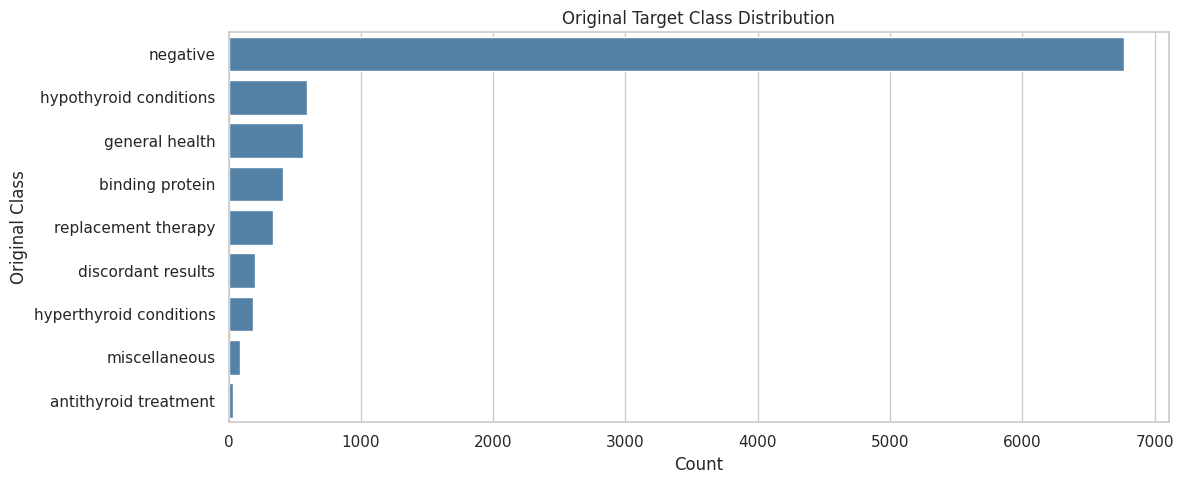

,label,count,percentage
0,No Disease (0),6770,73.82
1,Disease (1),2401,26.18


Saved plot: binary_class_distribution.png


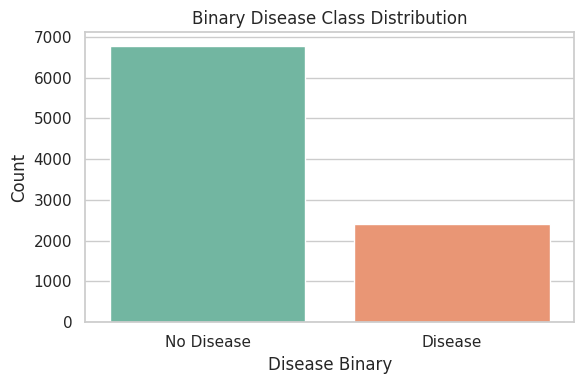

In [5]:
# ==========================================
# 5. Target variable analysis
# ==========================================
if "class" not in df.columns:
    raise KeyError("Expected target column 'class' was not found after column cleaning.")

df["class"] = df["class"].astype(str).str.strip().str.lower()

print("Unique target labels:")
display(pd.Series(sorted(df["class"].dropna().unique()), name="class_labels"))

class_counts = df["class"].value_counts(dropna=False)
class_pct = df["class"].value_counts(normalize=True, dropna=False).mul(100).round(2)

target_summary = pd.DataFrame({"count": class_counts, "percentage": class_pct})
display(target_summary)

plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="class", order=class_counts.index, color="steelblue")
plt.title("Original Target Class Distribution")
plt.xlabel("Count")
plt.ylabel("Original Class")
plt.tight_layout()
safe_savefig("original_class_distribution.png")
plt.show()

# Binary target creation
df["disease_binary"] = np.where(df["class"] == "negative", 0, 1)

binary_counts = df["disease_binary"].value_counts().sort_index()
binary_pct = df["disease_binary"].value_counts(normalize=True).sort_index().mul(100).round(2)
binary_summary = pd.DataFrame({
    "label": ["No Disease (0)", "Disease (1)"],
    "count": [binary_counts.get(0, 0), binary_counts.get(1, 0)],
    "percentage": [binary_pct.get(0, 0), binary_pct.get(1, 0)]
})
display(binary_summary)

plt.figure(figsize=(6, 4))
sns.countplot(x=df["disease_binary"], palette="Set2")
plt.title("Binary Disease Class Distribution")
plt.xlabel("Disease Binary")
plt.ylabel("Count")
plt.xticks([0, 1], ["No Disease", "Disease"])
plt.tight_layout()
safe_savefig("binary_class_distribution.png")
plt.show()

### Interpretation
- The original target is **multiclass**, containing several thyroid-related diagnostic categories.
- For the main predictive pipeline, the outcome is converted into **binary screening form**:  
  **0 = No Disease**, **1 = Disease**.
- This transformation is academically reasonable because it simplifies interpretation, supports strong classification evaluation, and aligns with screening-oriented healthcare applications.
- A multiclass extension remains a suitable recommendation for future work.

In [6]:
# ==========================================
# 6. Data cleaning and preprocessing
# ==========================================
df_clean = df.copy()

# Remove exact duplicates
before_dups = df_clean.shape[0]
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
after_dups = df_clean.shape[0]
print(f"Removed {before_dups - after_dups} duplicate rows.")

# Normalize common boolean-like text in object columns
for col in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[col] = df_clean[col].apply(normalize_bool_like)

# Safely coerce numeric-looking object columns to numeric
for col in df_clean.select_dtypes(include=["object"]).columns:
    converted = pd.to_numeric(df_clean[col], errors="coerce")
    ratio = converted.notna().mean()
    # Convert only if a strong majority of non-null values are numeric-like
    if ratio > 0.80 and col not in ["class", "referral_source", "sex"]:
        df_clean[col] = converted

# Recalculate dtypes after coercion
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [col for col in df_clean.columns if col not in numeric_cols]

# Impute missing values
for col in numeric_cols:
    if df_clean[col].isna().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    if df_clean[col].isna().sum() > 0:
        mode_vals = df_clean[col].mode(dropna=True)
        fill_val = mode_vals.iloc[0] if not mode_vals.empty else "unknown"
        df_clean[col] = df_clean[col].fillna(fill_val)

# Outlier capping for major numeric thyroid measures if present
major_numeric_candidates = ["age", "tsh", "t3", "tt4", "t4u", "fti"]
outlier_report = []
for col in major_numeric_candidates:
    if col in df_clean.columns and pd.api.types.is_numeric_dtype(df_clean[col]):
        original = df_clean[col].copy()
        df_clean[col], lower, upper = outlier_cap_iqr(df_clean[col])
        changed = (original != df_clean[col]).sum()
        outlier_report.append({"column": col, "lower_cap": lower, "upper_cap": upper, "values_capped": int(changed)})

outlier_report_df = pd.DataFrame(outlier_report)
display(outlier_report_df if not outlier_report_df.empty else pd.DataFrame({"message": ["No outlier capping applied."]}))

print("Final data types after cleaning:")
display(df_clean.dtypes.to_frame("dtype"))

print("Missing values after preprocessing:")
display(df_clean.isna().sum().to_frame("missing_count"))

print("Cleaned dataset shape:", df_clean.shape)

Removed 102 duplicate rows.


,column,lower_cap,upper_cap,values_capped
0,age,-9.50,114.50,4
1,tsh,-2.50,5.66,944
2,t3,0.95,2.95,1035
3,tt4,32.50,180.50,496
4,t4u,0.60,1.32,542
5,fti,48.50,172.50,638


Final data types after cleaning:


,dtype
age,float64
sex,object
on_thyroxine,bool
query_on_thyroxine,bool
on_antithyroid_medication,bool
sick,bool
pregnant,bool
thyroid_surgery,bool
i131_treatment,bool
query_hypothyroid,bool


Missing values after preprocessing:


,missing_count
age,0
sex,0
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_medication,0
sick,0
pregnant,0
thyroid_surgery,0
i131_treatment,0
query_hypothyroid,0


Cleaned dataset shape: (9069, 24)


### Interpretation
- Duplicates were removed to avoid repeated patient records affecting the analysis.
- Missing values were handled using median imputation for numeric variables and mode imputation for categorical variables.
- Extreme outliers were capped using the IQR method instead of deleting many rows, which preserves sample size while limiting the influence of extreme values.
- The cleaned dataset is now suitable for descriptive analysis, inferential testing, and machine learning.

In [7]:
# ==========================================
# 7. Data understanding and feature grouping
# ==========================================
all_cols = df_clean.columns.tolist()

demographic_features = [c for c in all_cols if any(k in c for k in ["age", "sex", "gender"])]
hormone_features = [c for c in all_cols if any(k in c for k in ["tsh", "t3", "tt4", "t4u", "fti", "thyrox"])]
medication_history_features = [c for c in all_cols if any(k in c for k in [
    "on_", "query_", "sick", "pregnant", "surgery", "treatment", "lithium", "goitre", "tumor", "hypopituitary", "psych"
])]
referral_features = [c for c in all_cols if "referral" in c]
target_features = [c for c in all_cols if c in ["class", "disease_binary"]]

feature_groups = {
    "Demographic Features": demographic_features,
    "Hormone Measurement Features": hormone_features,
    "Medication/History Features": medication_history_features,
    "Referral Features": referral_features,
    "Target Features": target_features
}

for group, cols in feature_groups.items():
    print(f"\n{group}:")
    print(cols if cols else "None detected")


Demographic Features:
['age', 'sex']

Hormone Measurement Features:
['on_thyroxine', 'query_on_thyroxine', 'tsh', 't3', 'tt4', 't4u', 'fti']

Medication/History Features:
['on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'i131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych']

Referral Features:
['referral_source']

Target Features:
['class', 'disease_binary']


### Interpretation
The dataset combines demographic variables, hormone measurements, clinical history indicators, and referral-related information. These variables are relevant because thyroid disease diagnosis often depends on both laboratory values and clinical context. Grouping features in this way improves project clarity and supports domain-based interpretation.

In [8]:
# ==========================================
# 8. Descriptive statistics
# ==========================================
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols_no_target = [c for c in numeric_cols if c not in ["disease_binary"]]

desc_tables = []
for col in numeric_cols_no_target:
    s = df_clean[col]
    mode_val = s.mode(dropna=True)
    desc_tables.append({
        "variable": col,
        "count": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "mode": mode_val.iloc[0] if not mode_val.empty else np.nan,
        "std_dev": s.std(),
        "variance": s.var(),
        "min": s.min(),
        "q1": s.quantile(0.25),
        "q3": s.quantile(0.75),
        "iqr": s.quantile(0.75) - s.quantile(0.25),
        "max": s.max(),
        "skewness": s.skew(),
        "kurtosis": s.kurt()
    })

descriptive_numeric_df = pd.DataFrame(desc_tables).sort_values("variable")
display(descriptive_numeric_df)

cat_tables = []
for col in df_clean.select_dtypes(exclude=[np.number]).columns:
    vc = df_clean[col].value_counts(dropna=False)
    pct = df_clean[col].value_counts(normalize=True, dropna=False).mul(100).round(2)
    temp = pd.DataFrame({"variable": col, "category": vc.index.astype(str), "count": vc.values, "percentage": pct.values})
    cat_tables.append(temp)

descriptive_categorical_df = pd.concat(cat_tables, ignore_index=True) if cat_tables else pd.DataFrame()
display(descriptive_categorical_df.head(50))

try:
    descriptive_numeric_df.to_csv(os.path.join(OUTPUT_DIR, "descriptive_numeric_statistics.csv"), index=False)
    descriptive_categorical_df.to_csv(os.path.join(OUTPUT_DIR, "descriptive_categorical_statistics.csv"), index=False)
except Exception as e:
    print(f"Could not save descriptive statistics: {e}")

,variable,count,mean,median,mode,std_dev,variance,min,q1,q3,iqr,max,skewness,kurtosis
0,age,9069,52.225824,55.00,62.00,18.959213,359.451755,1.000,37.00,68.00,31.00,114.50,-0.217017,-0.839336
5,fti,9069,111.376668,109.00,109.00,27.391805,750.310962,48.500,95.00,126.00,31.00,172.50,0.264118,0.168775
2,t3,9069,1.913661,1.90,1.90,0.493127,0.243175,0.950,1.70,2.20,0.50,2.95,0.108588,0.000311
4,t4u,9069,0.966329,0.96,0.96,0.157439,0.024787,0.600,0.87,1.05,0.18,1.32,0.206250,0.111158
1,tsh,9069,1.877765,1.40,1.40,1.726779,2.981765,0.005,0.56,2.60,2.04,5.66,1.086701,0.092375
3,tt4,9069,107.440512,104.00,104.00,31.246189,976.324345,32.500,88.00,125.00,37.00,180.50,0.307621,0.215791


,variable,category,count,percentage
0,sex,0,6288,69.34
1,sex,M,2781,30.66
2,on_thyroxine,False,7832,86.36
3,on_thyroxine,True,1237,13.64
4,query_on_thyroxine,False,8916,98.31
5,query_on_thyroxine,True,153,1.69
6,on_antithyroid_medication,False,8954,98.73
7,on_antithyroid_medication,True,115,1.27
8,sick,False,8726,96.22
9,sick,True,343,3.78


### Interpretation
- Descriptive statistics summarize the central tendency and spread of the numeric variables.
- Hormone variables with large standard deviation or strong skewness may indicate heterogeneous patient profiles or the presence of clinically distinct groups.
- Categorical frequency tables show whether certain categories are highly imbalanced, which is important for both statistical interpretation and model training.

Saved plot: age_distribution.png


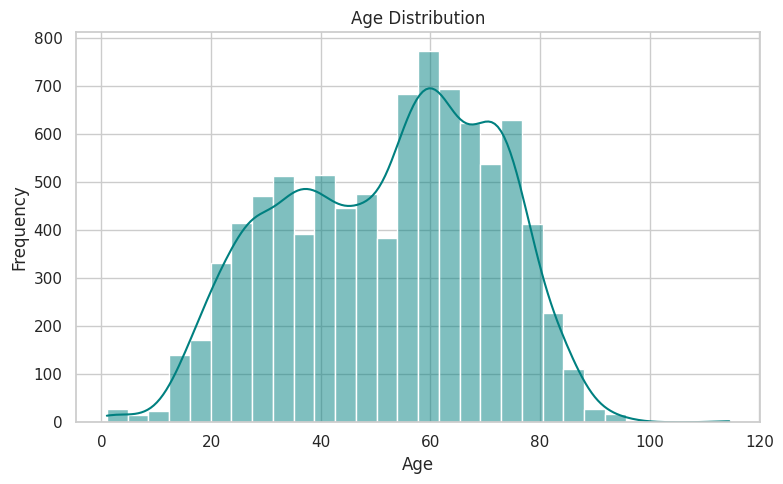

**Interpretation:** The age distribution shows how the sample is spread across age groups and whether the data is concentrated in younger, middle-aged, or older patients.

Saved plot: sex_distribution.png


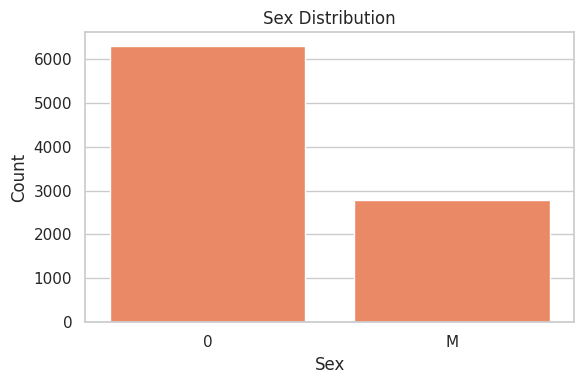

**Interpretation:** The sex distribution indicates whether the dataset is balanced across male and female patients, which is relevant because thyroid disorders are often more common in females.

Saved plot: age_by_disease.png


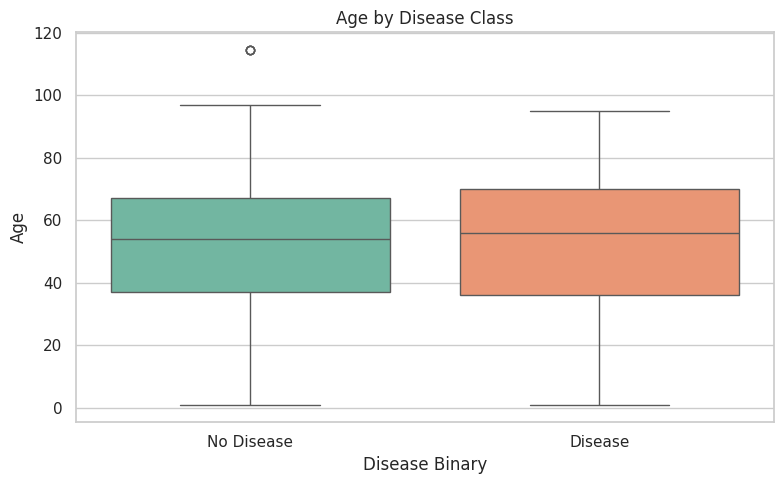

**Interpretation:** Comparing age across disease groups helps assess whether the disease-positive patients tend to be older or younger than disease-negative patients.

Saved plot: tsh_histogram.png


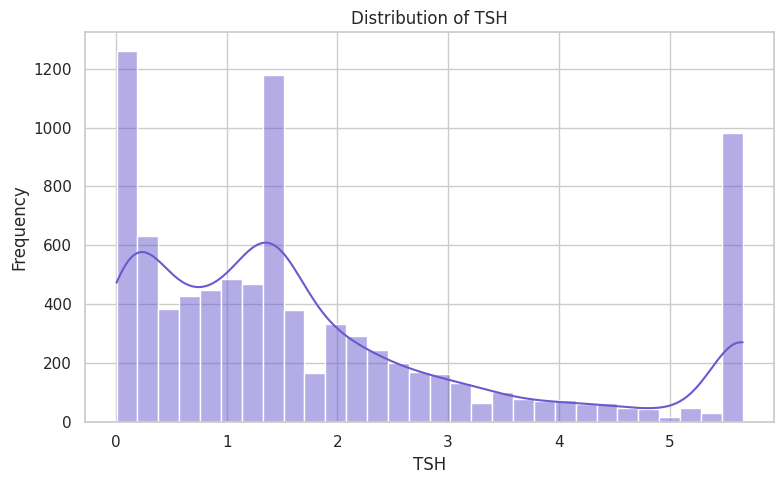

**Interpretation:** The histogram of TSH helps assess the shape of the distribution, presence of skewness, and concentration of observations.

Saved plot: t3_histogram.png


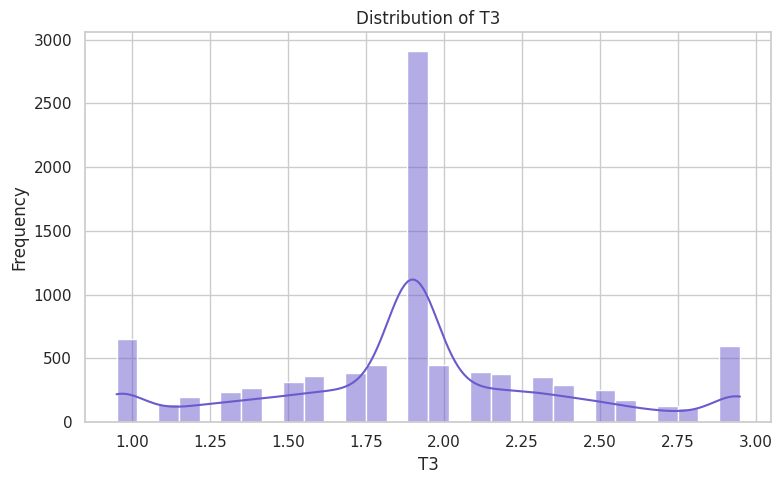

**Interpretation:** The histogram of T3 helps assess the shape of the distribution, presence of skewness, and concentration of observations.

Saved plot: tt4_histogram.png


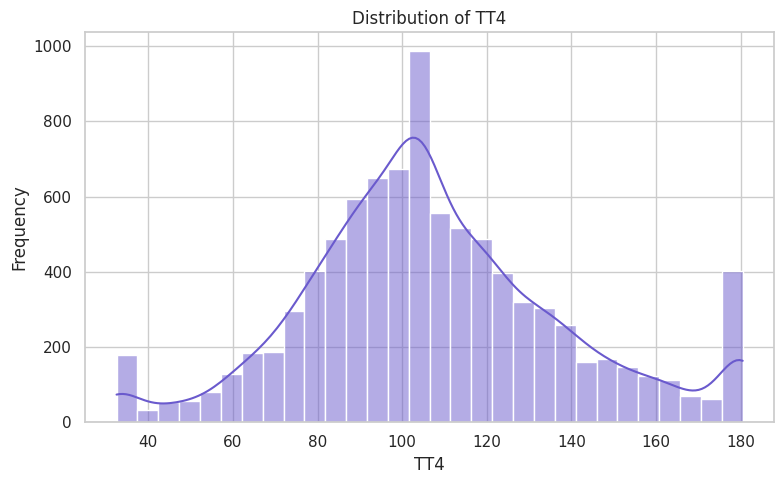

**Interpretation:** The histogram of TT4 helps assess the shape of the distribution, presence of skewness, and concentration of observations.

Saved plot: t4u_histogram.png


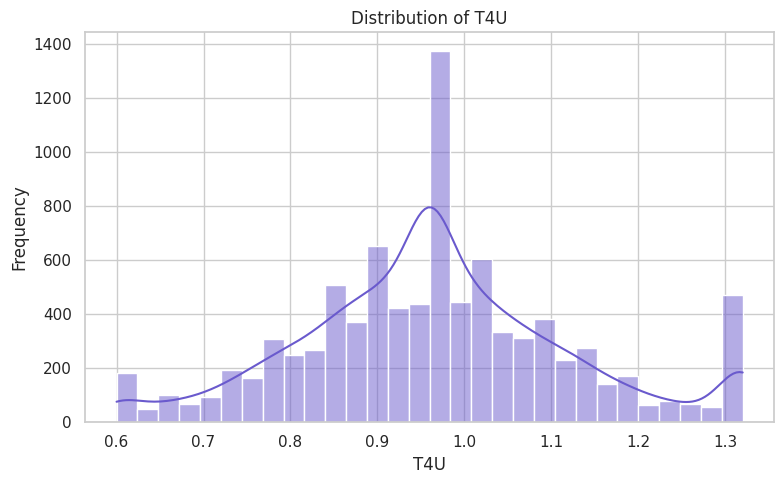

**Interpretation:** The histogram of T4U helps assess the shape of the distribution, presence of skewness, and concentration of observations.

Saved plot: fti_histogram.png


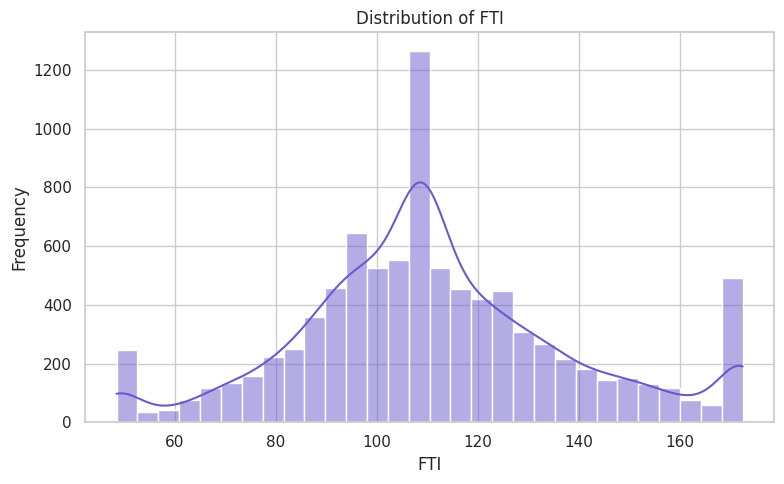

**Interpretation:** The histogram of FTI helps assess the shape of the distribution, presence of skewness, and concentration of observations.

Saved plot: major_numeric_boxplots.png


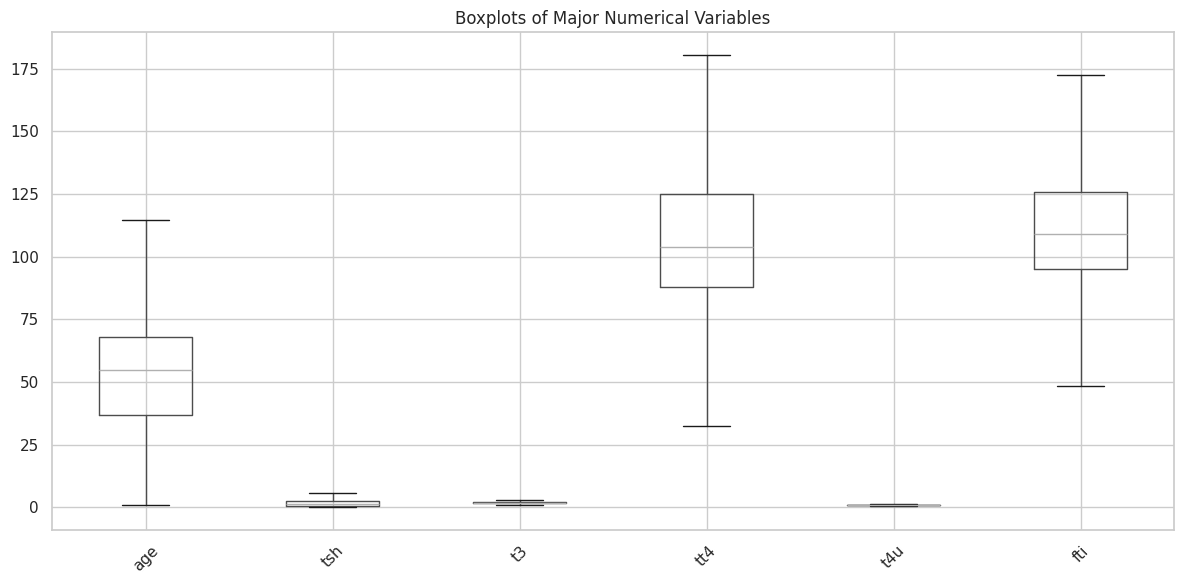

**Interpretation:** Boxplots help compare variability and identify remaining unusual values in the major numerical variables.

Saved plot: tsh_by_disease_boxplot.png


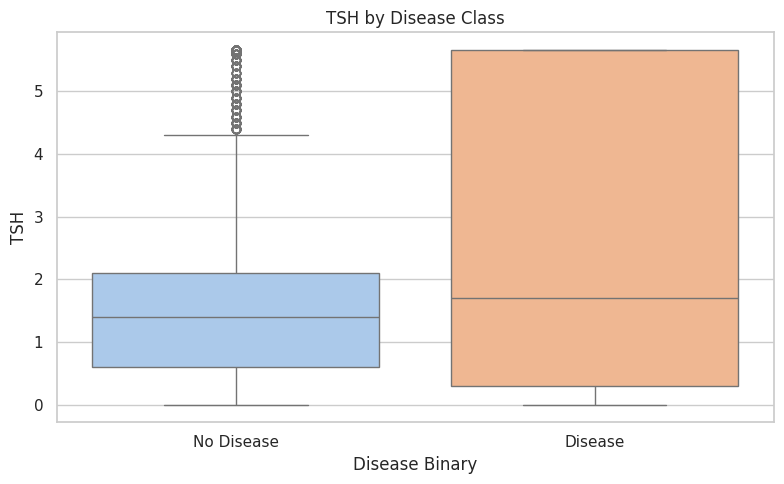

**Interpretation:** Differences in TSH across disease groups may indicate whether this hormone measurement is clinically informative for disease detection.

Saved plot: t3_by_disease_boxplot.png


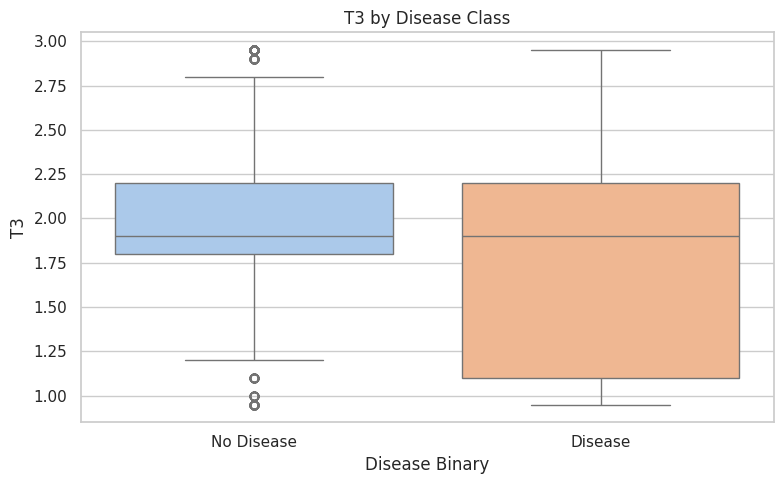

**Interpretation:** Differences in T3 across disease groups may indicate whether this hormone measurement is clinically informative for disease detection.

Saved plot: tt4_by_disease_boxplot.png


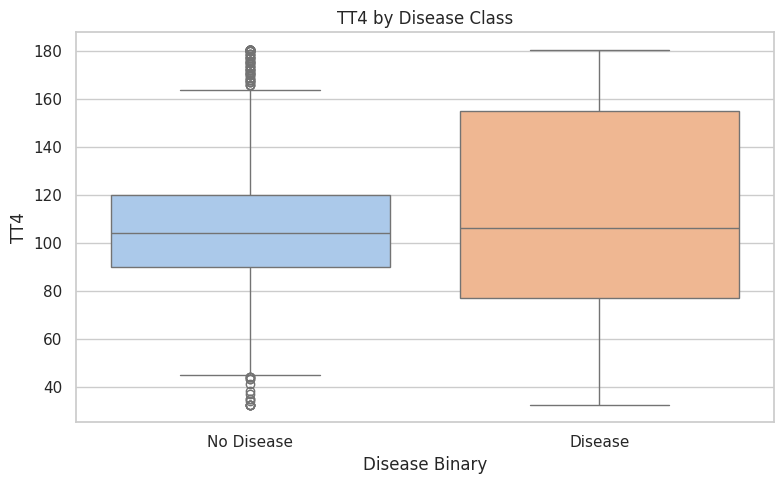

**Interpretation:** Differences in TT4 across disease groups may indicate whether this hormone measurement is clinically informative for disease detection.

Saved plot: t4u_by_disease_boxplot.png


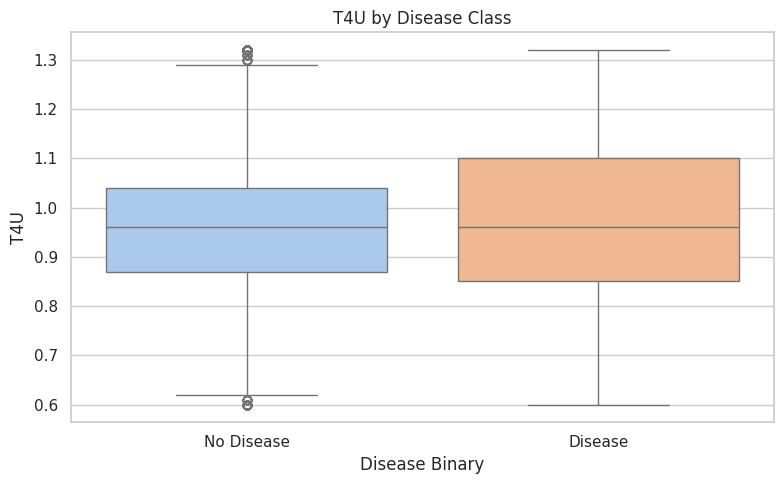

**Interpretation:** Differences in T4U across disease groups may indicate whether this hormone measurement is clinically informative for disease detection.

Saved plot: fti_by_disease_boxplot.png


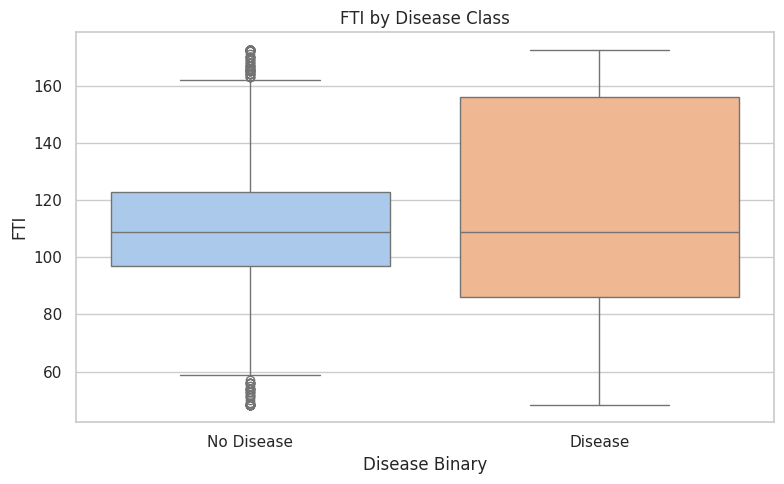

**Interpretation:** Differences in FTI across disease groups may indicate whether this hormone measurement is clinically informative for disease detection.

Saved plot: correlation_heatmap.png


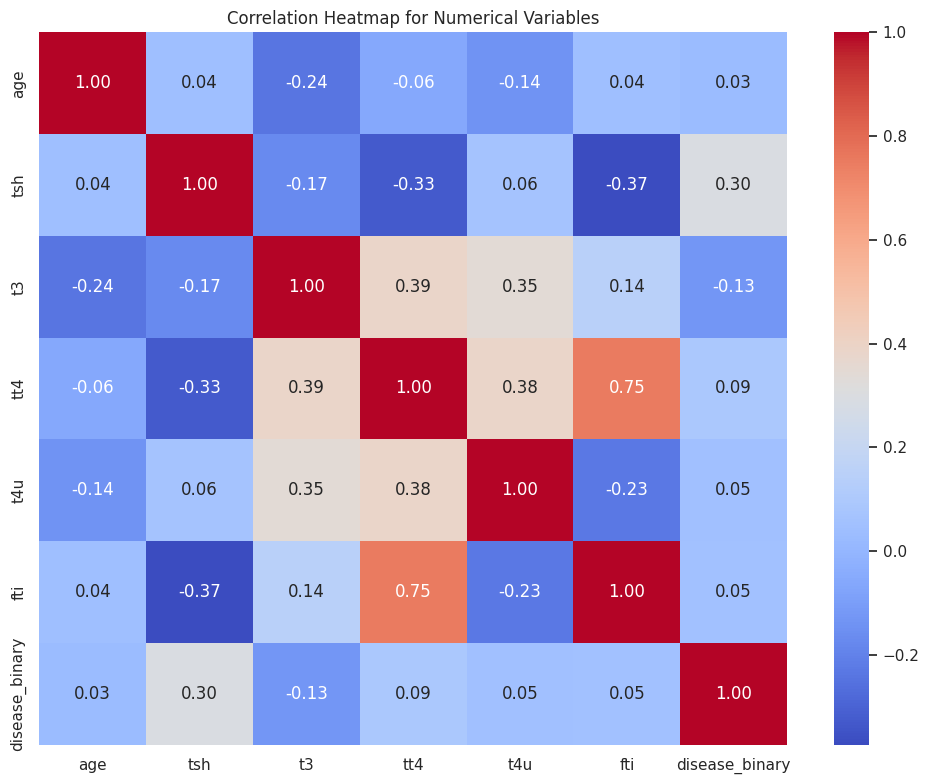

**Interpretation:** The heatmap shows linear associations among numeric variables and helps identify potentially important predictors and multicollinearity.

Saved plot: pairplot_selected_features.png


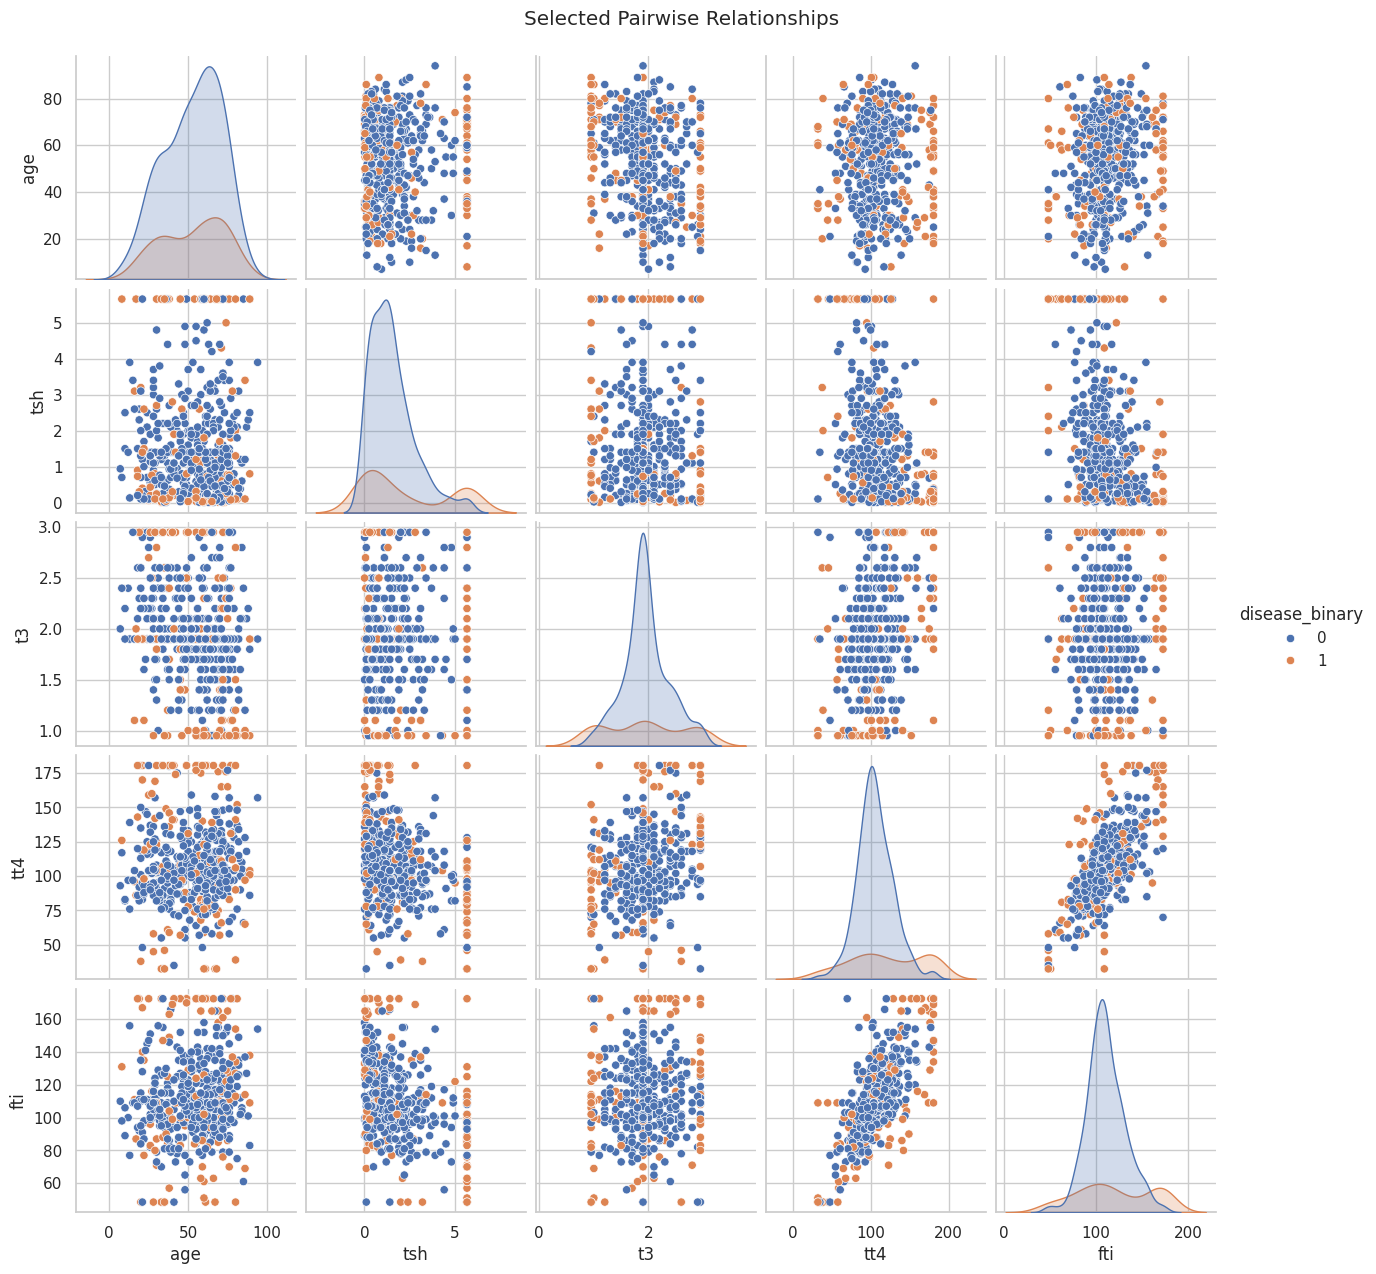

**Interpretation:** Pairwise plots help visualize cluster separation, linearity, and interactions between the most relevant numeric features.

Saved plot: on_thyroxine_countplot_by_disease.png


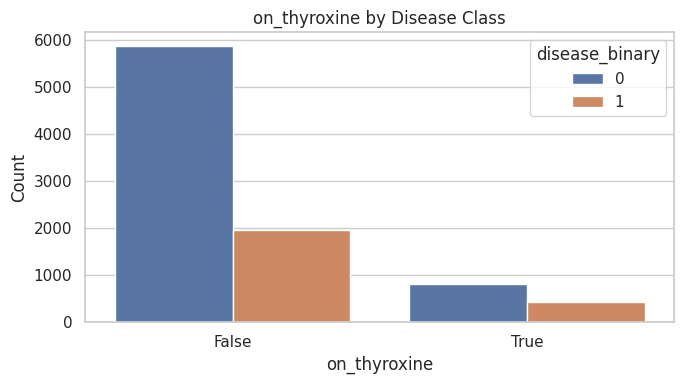

**Interpretation:** This countplot shows how the clinical indicator **on_thyroxine** is distributed across the disease groups.

Saved plot: query_on_thyroxine_countplot_by_disease.png


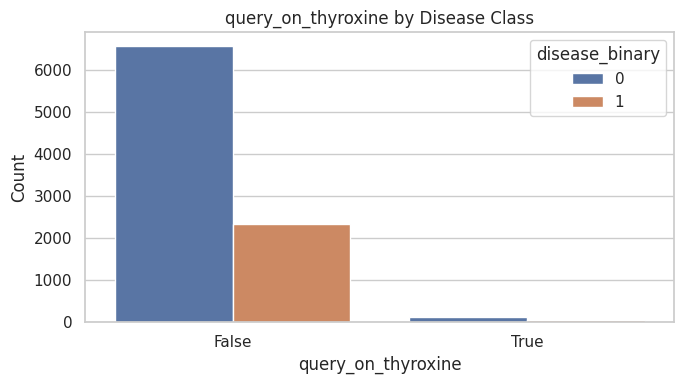

**Interpretation:** This countplot shows how the clinical indicator **query_on_thyroxine** is distributed across the disease groups.

Saved plot: on_antithyroid_medication_countplot_by_disease.png


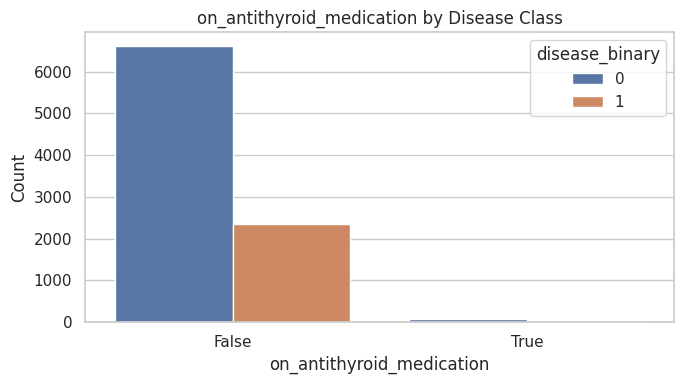

**Interpretation:** This countplot shows how the clinical indicator **on_antithyroid_medication** is distributed across the disease groups.

Saved plot: sick_countplot_by_disease.png


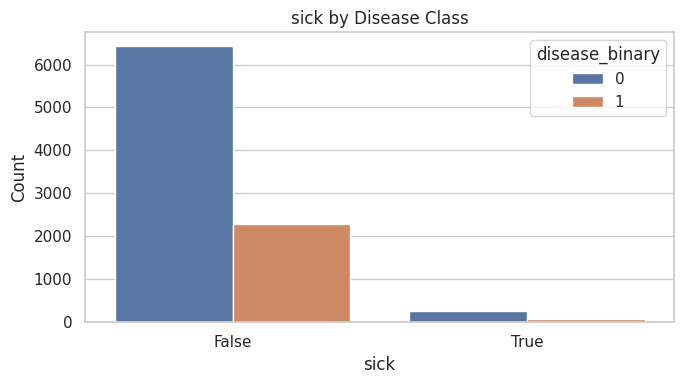

**Interpretation:** This countplot shows how the clinical indicator **sick** is distributed across the disease groups.

Saved plot: pregnant_countplot_by_disease.png


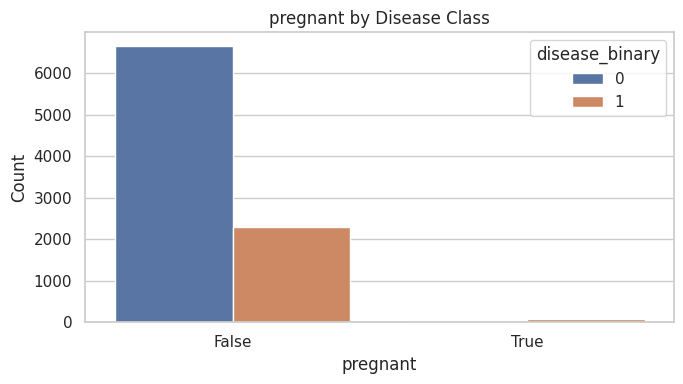

**Interpretation:** This countplot shows how the clinical indicator **pregnant** is distributed across the disease groups.

Saved plot: thyroid_surgery_countplot_by_disease.png


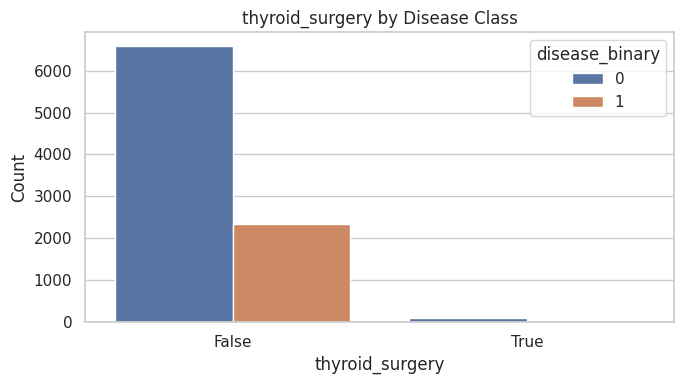

**Interpretation:** This countplot shows how the clinical indicator **thyroid_surgery** is distributed across the disease groups.

Saved plot: i131_treatment_countplot_by_disease.png


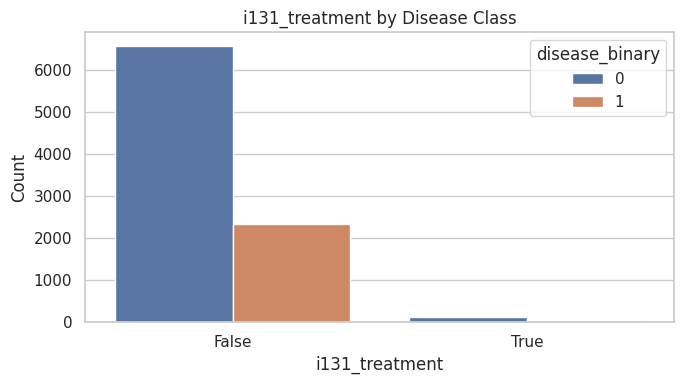

**Interpretation:** This countplot shows how the clinical indicator **i131_treatment** is distributed across the disease groups.

Saved plot: query_hypothyroid_countplot_by_disease.png


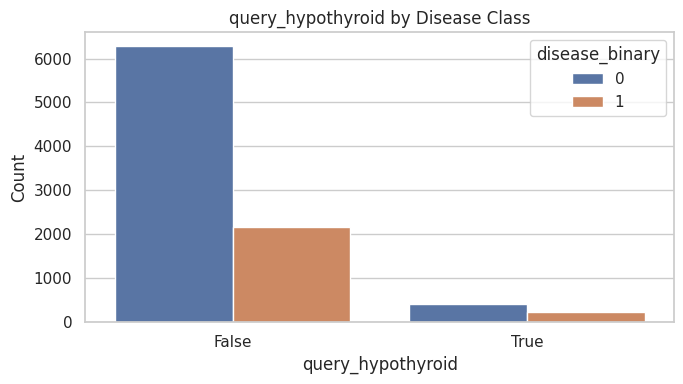

**Interpretation:** This countplot shows how the clinical indicator **query_hypothyroid** is distributed across the disease groups.

Saved plot: referral_source_distribution.png


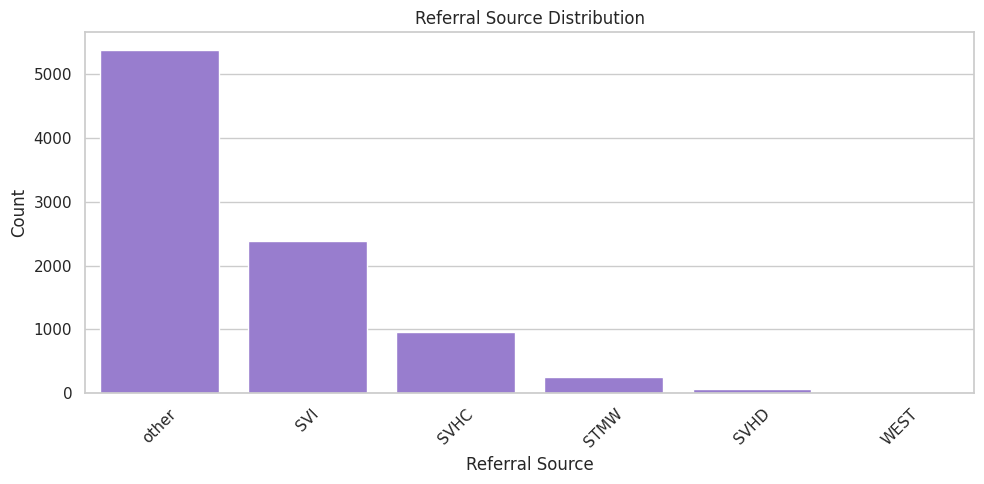

**Interpretation:** Referral source distribution indicates how patients entered the diagnostic workflow and whether some referral channels dominate the sample.

In [9]:
# ==========================================
# 9. Exploratory Data Analysis (EDA)
# ==========================================
# A. Target plots already created above. Here we proceed with demographic, hormone, and clinical plots.

# Demographic plots
if "age" in df_clean.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df_clean["age"], bins=30, kde=True, color="teal")
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.tight_layout()
    safe_savefig("age_distribution.png")
    plt.show()
    print_md("**Interpretation:** The age distribution shows how the sample is spread across age groups and whether the data is concentrated in younger, middle-aged, or older patients.")

if "sex" in df_clean.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df_clean, x="sex", color="coral")
    plt.title("Sex Distribution")
    plt.xlabel("Sex")
    plt.ylabel("Count")
    plt.tight_layout()
    safe_savefig("sex_distribution.png")
    plt.show()
    print_md("**Interpretation:** The sex distribution indicates whether the dataset is balanced across male and female patients, which is relevant because thyroid disorders are often more common in females.")

if all(c in df_clean.columns for c in ["age", "disease_binary"]):
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df_clean, x="disease_binary", y="age", palette="Set2")
    plt.title("Age by Disease Class")
    plt.xlabel("Disease Binary")
    plt.ylabel("Age")
    plt.xticks([0, 1], ["No Disease", "Disease"])
    plt.tight_layout()
    safe_savefig("age_by_disease.png")
    plt.show()
    print_md("**Interpretation:** Comparing age across disease groups helps assess whether the disease-positive patients tend to be older or younger than disease-negative patients.")

# Hormone-related plots
for col in ["tsh", "t3", "tt4", "t4u", "fti"]:
    if col in df_clean.columns:
        plt.figure(figsize=(8, 5))
        sns.histplot(df_clean[col], bins=30, kde=True, color="slateblue")
        plt.title(f"Distribution of {col.upper()}")
        plt.xlabel(col.upper())
        plt.ylabel("Frequency")
        plt.tight_layout()
        safe_savefig(f"{col}_histogram.png")
        plt.show()
        print_md(f"**Interpretation:** The histogram of {col.upper()} helps assess the shape of the distribution, presence of skewness, and concentration of observations.")

major_present = [c for c in ["age", "tsh", "t3", "tt4", "t4u", "fti"] if c in df_clean.columns]
if major_present:
    plt.figure(figsize=(12, 6))
    df_clean[major_present].boxplot(rot=45)
    plt.title("Boxplots of Major Numerical Variables")
    plt.tight_layout()
    safe_savefig("major_numeric_boxplots.png")
    plt.show()
    print_md("**Interpretation:** Boxplots help compare variability and identify remaining unusual values in the major numerical variables.")

for col in ["tsh", "t3", "tt4", "t4u", "fti"]:
    if col in df_clean.columns and "disease_binary" in df_clean.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df_clean, x="disease_binary", y=col, palette="pastel")
        plt.title(f"{col.upper()} by Disease Class")
        plt.xlabel("Disease Binary")
        plt.ylabel(col.upper())
        plt.xticks([0, 1], ["No Disease", "Disease"])
        plt.tight_layout()
        safe_savefig(f"{col}_by_disease_boxplot.png")
        plt.show()
        print_md(f"**Interpretation:** Differences in {col.upper()} across disease groups may indicate whether this hormone measurement is clinically informative for disease detection.")

# Correlation heatmap
if len(numeric_cols_no_target) >= 2:
    corr_matrix = df_clean[numeric_cols_no_target + ["disease_binary"]].corr(numeric_only=True)
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap for Numerical Variables")
    plt.tight_layout()
    safe_savefig("correlation_heatmap.png")
    plt.show()
    print_md("**Interpretation:** The heatmap shows linear associations among numeric variables and helps identify potentially important predictors and multicollinearity.")

selected_pairplot_cols = [c for c in ["age", "tsh", "t3", "tt4", "fti", "disease_binary"] if c in df_clean.columns]
if len(selected_pairplot_cols) >= 3:
    try:
        sns.pairplot(df_clean[selected_pairplot_cols].sample(min(500, len(df_clean)), random_state=RANDOM_STATE), hue="disease_binary")
        plt.suptitle("Selected Pairwise Relationships", y=1.02)
        safe_savefig("pairplot_selected_features.png")
        plt.show()
        print_md("**Interpretation:** Pairwise plots help visualize cluster separation, linearity, and interactions between the most relevant numeric features.")
    except Exception as e:
        print(f"Pairplot skipped: {e}")

# Categorical and clinical indicator plots
clinical_indicator_candidates = [c for c in df_clean.columns if c not in ["class", "sex", "referral_source"] and df_clean[c].nunique(dropna=True) <= 3 and c != "disease_binary"]
for col in clinical_indicator_candidates[:8]:
    try:
        plt.figure(figsize=(7, 4))
        sns.countplot(data=df_clean, x=col, hue="disease_binary")
        plt.title(f"{col} by Disease Class")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.tight_layout()
        safe_savefig(f"{col}_countplot_by_disease.png")
        plt.show()
        print_md(f"**Interpretation:** This countplot shows how the clinical indicator **{col}** is distributed across the disease groups.")
    except Exception as e:
        print(f"Countplot skipped for {col}: {e}")

if "referral_source" in df_clean.columns:
    plt.figure(figsize=(10, 5))
    order = df_clean["referral_source"].value_counts().index
    sns.countplot(data=df_clean, x="referral_source", order=order, color="mediumpurple")
    plt.title("Referral Source Distribution")
    plt.xlabel("Referral Source")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    safe_savefig("referral_source_distribution.png")
    plt.show()
    print_md("**Interpretation:** Referral source distribution indicates how patients entered the diagnostic workflow and whether some referral channels dominate the sample.")

## Assumption Checking for Statistical Tests
Before selecting hypothesis tests, it is important to check whether the assumptions of parametric testing are reasonably met. In this project, normality and homogeneity of variance are tested for key numeric variables by disease group.

In [10]:
# ==========================================
# 10. Assumption checking
# ==========================================
assumption_results = []

for col in [c for c in ["tsh", "t3", "tt4", "t4u", "fti", "age"] if c in df_clean.columns]:
    group0 = df_clean.loc[df_clean["disease_binary"] == 0, col].dropna()
    group1 = df_clean.loc[df_clean["disease_binary"] == 1, col].dropna()

    # Shapiro-Wilk is computationally safer on sampled data if groups are large
    g0_sample = group0.sample(min(500, len(group0)), random_state=RANDOM_STATE) if len(group0) > 3 else group0
    g1_sample = group1.sample(min(500, len(group1)), random_state=RANDOM_STATE) if len(group1) > 3 else group1

    shapiro_p0 = np.nan
    shapiro_p1 = np.nan
    levene_p = np.nan

    try:
        if len(g0_sample) >= 3:
            shapiro_p0 = shapiro(g0_sample)[1]
        if len(g1_sample) >= 3:
            shapiro_p1 = shapiro(g1_sample)[1]
        if len(group0) >= 3 and len(group1) >= 3:
            levene_p = levene(group0, group1)[1]
    except Exception as e:
        print(f"Assumption test issue for {col}: {e}")

    assumption_results.append({
        "variable": col,
        "shapiro_p_group0": shapiro_p0,
        "shapiro_p_group1": shapiro_p1,
        "levene_p": levene_p,
        "normal_group0": shapiro_p0 > 0.05 if pd.notna(shapiro_p0) else np.nan,
        "normal_group1": shapiro_p1 > 0.05 if pd.notna(shapiro_p1) else np.nan,
        "equal_variance": levene_p > 0.05 if pd.notna(levene_p) else np.nan
    })

assumption_df = pd.DataFrame(assumption_results)
display(assumption_df)

,variable,shapiro_p_group0,shapiro_p_group1,levene_p,normal_group0,normal_group1,equal_variance
0,tsh,7.586052e-18,2.216273e-25,0.000000e+00,False,False,False
1,t3,7.585564e-11,4.693659e-18,1.891425e-217,False,False,False
2,tt4,3.349067e-04,2.871973e-12,0.000000e+00,False,False,False
3,t4u,9.507032e-05,3.184783e-11,4.721934e-81,False,False,False
4,fti,6.798989e-05,2.093641e-15,0.000000e+00,False,False,False
5,age,7.550214e-08,1.692717e-09,3.269250e-04,False,False,False


### Interpretation
- A **Shapiro-Wilk p-value greater than 0.05** suggests that the sampled values do not significantly deviate from normality.
- A **Levene’s test p-value greater than 0.05** suggests that the group variances are reasonably similar.
- If these assumptions are not satisfied, non-parametric tests such as the **Mann-Whitney U test** are more appropriate than an independent samples t-test.

In [11]:
# ==========================================
# 11. Inferential statistical analysis
# ==========================================
inferential_results = []

# A. Hypothesis testing for numeric variables
for col in [c for c in ["tsh", "t3", "tt4", "t4u", "fti", "age"] if c in df_clean.columns]:
    group0 = df_clean.loc[df_clean["disease_binary"] == 0, col].dropna()
    group1 = df_clean.loc[df_clean["disease_binary"] == 1, col].dropna()

    if len(group0) < 3 or len(group1) < 3:
        inferential_results.append({
            "variable": col,
            "test_used": "Insufficient data",
            "test_statistic": np.nan,
            "p_value": np.nan,
            "decision": "Not tested"
        })
        continue

    row = assumption_df.loc[assumption_df["variable"] == col]
    use_parametric = False
    if not row.empty:
        normal0 = bool(row["normal_group0"].iloc[0]) if pd.notna(row["normal_group0"].iloc[0]) else False
        normal1 = bool(row["normal_group1"].iloc[0]) if pd.notna(row["normal_group1"].iloc[0]) else False
        equal_var = bool(row["equal_variance"].iloc[0]) if pd.notna(row["equal_variance"].iloc[0]) else False
        use_parametric = normal0 and normal1 and equal_var

    try:
        if use_parametric:
            stat, p = ttest_ind(group0, group1, equal_var=True)
            test_used = "Independent t-test"
        else:
            stat, p = mannwhitneyu(group0, group1, alternative="two-sided")
            test_used = "Mann-Whitney U"
        decision = "Reject H0" if p < 0.05 else "Fail to Reject H0"
        inferential_results.append({
            "variable": col,
            "test_used": test_used,
            "test_statistic": stat,
            "p_value": p,
            "decision": decision
        })
    except Exception as e:
        inferential_results.append({
            "variable": col,
            "test_used": f"Error: {e}",
            "test_statistic": np.nan,
            "p_value": np.nan,
            "decision": "Not tested"
        })

inferential_df = pd.DataFrame(inferential_results)
display(inferential_df)

# B. Correlation analysis
numeric_corr_df = df_clean[[c for c in numeric_cols_no_target if c in df_clean.columns] + ["disease_binary"]].copy()
pearson_corr = numeric_corr_df.corr(method="pearson", numeric_only=True)["disease_binary"].sort_values(ascending=False)
spearman_corr = numeric_corr_df.corr(method="spearman", numeric_only=True)["disease_binary"].sort_values(ascending=False)

corr_compare_df = pd.DataFrame({
    "pearson_with_disease": pearson_corr,
    "spearman_with_disease": spearman_corr
}).drop(index="disease_binary", errors="ignore")
display(corr_compare_df)

# C. Chi-square analysis for selected categorical variables
chi_square_results = []
selected_cats = [c for c in ["sex", "referral_source"] if c in df_clean.columns]
selected_cats += [c for c in clinical_indicator_candidates[:8] if c in df_clean.columns]

seen = set()
selected_cats_unique = []
for c in selected_cats:
    if c not in seen and c != "disease_binary":
        selected_cats_unique.append(c)
        seen.add(c)

for col in selected_cats_unique:
    try:
        contingency = pd.crosstab(df_clean[col], df_clean["disease_binary"])
        if contingency.shape[0] >= 2 and contingency.shape[1] >= 2:
            chi2, p, dof, exp = chi2_contingency(contingency)
            chi_square_results.append({
                "variable": col,
                "chi2_statistic": chi2,
                "p_value": p,
                "degrees_of_freedom": dof,
                "decision": "Reject H0" if p < 0.05 else "Fail to Reject H0"
            })
    except Exception as e:
        chi_square_results.append({
            "variable": col,
            "chi2_statistic": np.nan,
            "p_value": np.nan,
            "degrees_of_freedom": np.nan,
            "decision": f"Error: {e}"
        })

chi_square_df = pd.DataFrame(chi_square_results)
display(chi_square_df)

,variable,test_used,test_statistic,p_value,decision
0,tsh,Mann-Whitney U,6486683.0,3.177842e-41,Reject H0
1,t3,Mann-Whitney U,9242135.0,1.265596e-32,Reject H0
2,tt4,Mann-Whitney U,7382593.5,1.411338e-07,Reject H0
3,t4u,Mann-Whitney U,7744662.0,4.956244e-02,Reject H0
4,fti,Mann-Whitney U,7790841.5,1.230581e-01,Fail to Reject H0
5,age,Mann-Whitney U,7614230.0,1.623206e-03,Reject H0


,pearson_with_disease,spearman_with_disease
age,0.028126,0.033097
fti,0.051105,0.016194
t3,-0.130302,-0.124907
t4u,0.050177,0.020622
tsh,0.297134,0.141218
tt4,0.091021,0.055277


,variable,chi2_statistic,p_value,degrees_of_freedom,decision
0,sex,71.471048,2.813564e-17,1,Reject H0
1,referral_source,203.215082,5.828459e-42,5,Reject H0
2,on_thyroxine,45.382210,1.621001e-11,1,Reject H0
3,query_on_thyroxine,0.000000,1.000000e+00,1,Fail to Reject H0
4,on_antithyroid_medication,0.849271,3.567587e-01,1,Fail to Reject H0
5,sick,0.883918,3.471309e-01,1,Fail to Reject H0
6,pregnant,114.550239,9.873287e-27,1,Reject H0
7,thyroid_surgery,0.278128,5.979308e-01,1,Fail to Reject H0
8,i131_treatment,0.143847,7.044860e-01,1,Fail to Reject H0
9,query_hypothyroid,27.414390,1.642048e-07,1,Reject H0


### Interpretation
- For numeric variables, the test used depends on whether parametric assumptions were reasonably satisfied.
- A significant p-value indicates that the distribution of that variable differs between disease-positive and disease-negative groups.
- Correlation analysis helps identify whether higher or lower values of numeric variables are associated with disease status.
- Chi-square tests assess whether categorical variables such as sex or clinical indicators show statistically significant association with disease status.

In [14]:
# ==========================================
# 12. Statistical predictive modeling: Logistic Regression
# ==========================================
model_df = df_clean.copy()

# Drop original multiclass target from X
target = "disease_binary"
exclude_from_X = ["class", "disease_binary"]
feature_cols = [c for c in model_df.columns if c not in exclude_from_X]

X = model_df[feature_cols].copy()
y = model_df[target].copy()

# Identify feature types
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

# To improve interpretability and stability, use a selected set of features if many columns exist
preferred_features = [c for c in ["age", "sex", "tsh", "t3", "tt4", "t4u", "fti", "on_thyroxine", "query_hypothyroid", "query_hyperthyroid"] if c in X.columns]
if len(preferred_features) >= 3:
    X_logit = X[preferred_features].copy()
else:
    X_logit = X.copy()

# Ensure categorical columns for X_logit are uniformly string type for OneHotEncoder
# The `sex` column is known to have mixed types (int and str) after initial cleaning.
# `on_thyroxine`, `query_hypothyroid`, `query_hyperthyroid` are also treated as categorical
# and should be string-typed for consistent one-hot encoding.
for col in ['sex', 'on_thyroxine', 'query_hypothyroid', 'query_hyperthyroid']:
    if col in X_logit.columns:
        X_logit[col] = X_logit[col].astype(str)

num_logit = X_logit.select_dtypes(include=[np.number]).columns.tolist()
cat_logit = [c for c in X_logit.columns if c not in num_logit]

preprocessor_logit = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_logit),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), cat_logit)
    ],
    remainder="drop"
)

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_logit, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

logit_model = Pipeline(steps=[
    ("preprocessor", preprocessor_logit),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
])

logit_model.fit(X_train_l, y_train_l)

# Get feature names after preprocessing
feature_names_num = num_logit
feature_names_cat = []
if cat_logit:
    try:
        ohe = logit_model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
        feature_names_cat = ohe.get_feature_names_out(cat_logit).tolist()
    except Exception:
        feature_names_cat = []

all_feature_names = feature_names_num + feature_names_cat

coefficients = logit_model.named_steps["classifier"].coef_[0]
coef_df = pd.DataFrame({
    "feature": all_feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients)
}).sort_values("odds_ratio", ascending=False)

display(coef_df.head(20))
display(coef_df.tail(20))


,feature,coefficient,odds_ratio
1,tsh,0.828159,2.289101
3,tt4,0.794251,2.212784
9,query_hyperthyroid_True,0.550546,1.734200
7,on_thyroxine_True,0.136951,1.146772
0,age,-0.003717,0.996290
8,query_hypothyroid_True,-0.006376,0.993644
5,fti,-0.057312,0.944299
4,t4u,-0.099706,0.905103
6,sex_M,-0.276804,0.758203
2,t3,-0.435199,0.647136


,feature,coefficient,odds_ratio
1,tsh,0.828159,2.289101
3,tt4,0.794251,2.212784
9,query_hyperthyroid_True,0.550546,1.734200
7,on_thyroxine_True,0.136951,1.146772
0,age,-0.003717,0.996290
8,query_hypothyroid_True,-0.006376,0.993644
5,fti,-0.057312,0.944299
4,t4u,-0.099706,0.905103
6,sex_M,-0.276804,0.758203
2,t3,-0.435199,0.647136


### Interpretation
- Logistic regression provides an interpretable statistical model for disease screening.
- A **positive coefficient** indicates that higher values (or the presence of a category) increase the log-odds of disease.
- An **odds ratio greater than 1** suggests increased odds of disease, whereas a value below 1 suggests lower odds.
- This section is useful because it combines statistical interpretation with predictive modeling.

,pearson_with_disease,spearman_with_disease
tsh,0.297134,0.141218
t3,-0.130302,-0.124907
tt4,0.091021,0.055277
age,0.028126,0.033097
t4u,0.050177,0.020622
fti,0.051105,0.016194


,feature,importance
15,tsh,0.255042
16,t3,0.218221
19,fti,0.167183
17,tt4,0.148690
18,t4u,0.090679
0,age,0.049156
1,on_thyroxine,0.008638
23,referral_source_SVI,0.008463
25,referral_source_other,0.008448
20,sex_M,0.008167


Saved plot: random_forest_feature_importance.png


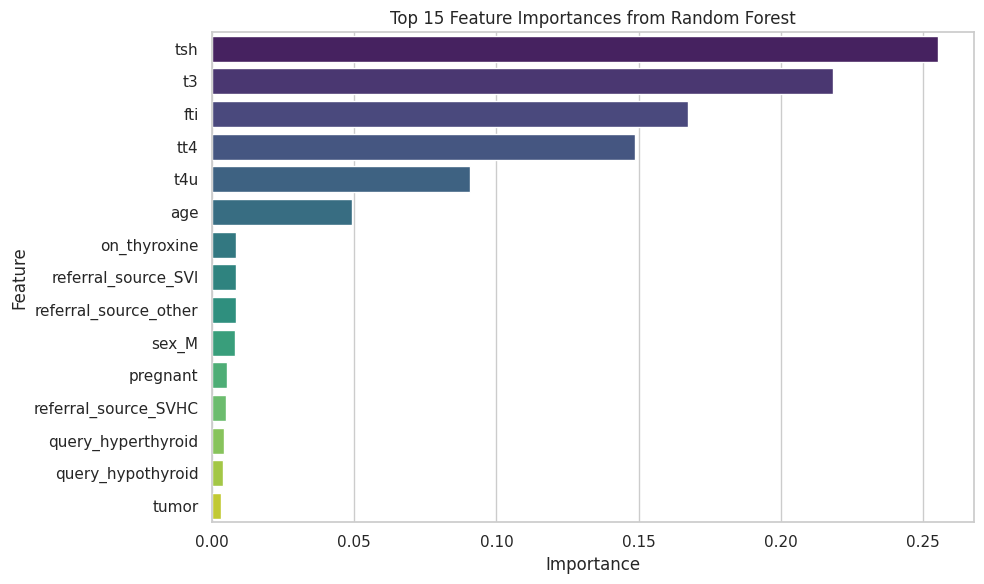

,feature,score
15,tsh,878.034170
16,t3,156.603749
5,pregnant,118.429375
21,referral_source_SVHC,107.919092
17,tt4,75.746172
20,sex_M,72.468069
14,psych,47.976078
1,on_thyroxine,46.074736
8,query_hypothyroid,27.988824
23,referral_source_SVI,25.280240


In [15]:
# ==========================================
# 13. Feature selection / importance
# ==========================================
# 1) Correlation-based review
corr_based = corr_compare_df.copy().sort_values("spearman_with_disease", key=lambda s: s.abs(), ascending=False)
display(corr_based)

# 2) Tree-based feature importance using a simple encoded dataset
X_fs = X.copy()
X_fs_encoded = pd.get_dummies(X_fs, drop_first=True)

# Ensure no missing values remain
for col in X_fs_encoded.columns:
    if X_fs_encoded[col].isna().sum() > 0:
        X_fs_encoded[col] = X_fs_encoded[col].fillna(X_fs_encoded[col].median())

rf_fs = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_fs.fit(X_fs_encoded, y)

rf_importance_df = pd.DataFrame({
    "feature": X_fs_encoded.columns,
    "importance": rf_fs.feature_importances_
}).sort_values("importance", ascending=False)

display(rf_importance_df.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(data=rf_importance_df.head(15), x="importance", y="feature", palette="viridis")
plt.title("Top 15 Feature Importances from Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
safe_savefig("random_forest_feature_importance.png")
plt.show()

# 3) Optional SelectKBest
try:
    selector = SelectKBest(score_func=f_classif, k=min(10, X_fs_encoded.shape[1]))
    selector.fit(X_fs_encoded, y)
    selected_features = X_fs_encoded.columns[selector.get_support()].tolist()
    selectkbest_df = pd.DataFrame({
        "feature": X_fs_encoded.columns,
        "score": selector.scores_
    }).sort_values("score", ascending=False)
    display(selectkbest_df.head(15))
except Exception as e:
    selected_features = rf_importance_df.head(10)["feature"].tolist()
    print(f"SelectKBest skipped: {e}")

### Interpretation
Feature importance analysis helps identify which variables contribute most strongly to thyroid disease detection. When multiple methods agree on the same variables, confidence in their relevance increases. Hormone variables and specific clinical indicators are expected to rank highly if the dataset is clinically informative.

In [22]:
# ==========================================
# 14. Machine learning preparation
# ==========================================
X = df_clean[[c for c in df_clean.columns if c not in ["class", "disease_binary"]]].copy()
y = df_clean["disease_binary"].copy()

# Ensure categorical columns are uniformly string type for the OneHotEncoder
# This addresses the TypeError: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']
for col in X.select_dtypes(include=['object']).columns:
    X[col] = X[col].astype(str)

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Disease prevalence in training set:", y_train.mean().round(4))
print("Disease prevalence in test set:", y_test.mean().round(4))

Numeric features: ['age', 'tsh', 't3', 'tt4', 't4u', 'fti']
Categorical features: ['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'i131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'referral_source']
Train shape: (7255, 22)
Test shape: (1814, 22)
Disease prevalence in training set: 0.2624
Disease prevalence in test set: 0.2624


In [17]:
# ==========================================
# 15. Machine learning models
# ==========================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7)
}

fitted_models = {}
evaluation_rows = []
roc_data = {}

for model_name, estimator in models.items():
    print(f"\nTraining: {model_name}")
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    try:
        pipeline.fit(X_train, y_train)
        fitted_models[model_name] = pipeline

        y_pred = pipeline.predict(X_test)

        if hasattr(pipeline.named_steps["model"], "predict_proba"):
            y_score = pipeline.predict_proba(X_test)[:, 1]
        elif hasattr(pipeline.named_steps["model"], "decision_function"):
            y_score = pipeline.decision_function(X_test)
        else:
            y_score = None

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_score) if y_score is not None else np.nan

        evaluation_rows.append({
            "model": model_name,
            "accuracy": acc,
            "precision": prec,
            "recall": rec,
            "f1_score": f1,
            "roc_auc": roc_auc
        })

        roc_data[model_name] = {"y_pred": y_pred, "y_score": y_score}

        print(classification_report(y_test, y_pred, zero_division=0))
    except Exception as e:
        print(f"Model failed for {model_name}: {e}")


Training: Logistic Regression
Model failed for Logistic Regression: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

Training: Decision Tree
Model failed for Decision Tree: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

Training: Random Forest
Model failed for Random Forest: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

Training: Support Vector Machine
Model failed for Support Vector Machine: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

Training: K-Nearest Neighbors
Model failed for K-Nearest Neighbors: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']


No evaluation results found. Please check whether the models were trained and evaluation_rows was populated.
Saved plot: roc_curve_comparison.png


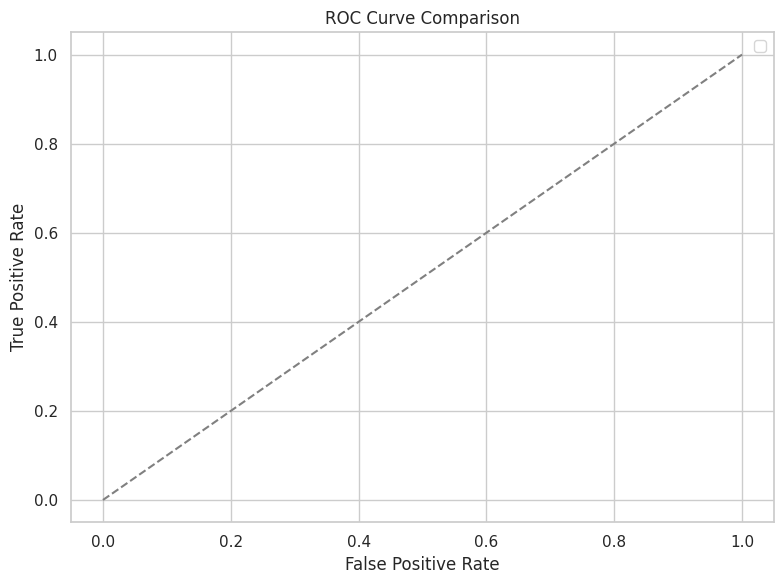

In [38]:
# ==========================================
# 16. Model evaluation
# ==========================================

evaluation_df = pd.DataFrame(evaluation_rows)

if evaluation_df.empty:
    print("No evaluation results found. Please check whether the models were trained and evaluation_rows was populated.")
else:
    print("Available evaluation columns:", evaluation_df.columns.tolist())

    # Standardize possible column names
    rename_map = {}
    if "f1" in evaluation_df.columns and "f1_score" not in evaluation_df.columns:
        rename_map["f1"] = "f1_score"
    if "auc" in evaluation_df.columns and "roc_auc" not in evaluation_df.columns:
        rename_map["auc"] = "roc_auc"

    evaluation_df = evaluation_df.rename(columns=rename_map)

    # Sort only by columns that actually exist
    sort_cols = [col for col in ["f1_score", "roc_auc"] if col in evaluation_df.columns]

    if sort_cols:
        evaluation_df = evaluation_df.sort_values(by=sort_cols, ascending=False)

    display(evaluation_df)

# Confusion matrices
for model_name, payload in roc_data.items():
    y_pred = payload["y_pred"]
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    safe_savefig(f"confusion_matrix_{clean_column_name(model_name)}.png")
    plt.show()

    print_md(f"**Interpretation for {model_name}:** The confusion matrix shows how well the model distinguishes disease-positive and disease-negative cases. In medical screening, recall is especially important because missing a true case may have clinical consequences.")

# ROC curves
plt.figure(figsize=(8, 6))
for model_name, payload in roc_data.items():
    y_score = payload.get("y_score", None)
    if y_score is not None:
        try:
            fpr, tpr, _ = roc_curve(y_test, y_score)
            auc_val = roc_auc_score(y_test, y_score)
            plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_val:.3f})")
        except Exception as e:
            print(f"ROC skipped for {model_name}: {e}")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
safe_savefig("roc_curve_comparison.png")
plt.show()

In [42]:
# ==========================================
# 17. Model comparison
# ==========================================

if evaluation_df.empty:
    print("evaluation_df is empty. Please check whether the model evaluation loop successfully added results to evaluation_rows.")
else:
    print("Available columns in evaluation_df:", evaluation_df.columns.tolist())

    # Standardize column names if needed
    rename_map = {}
    if "f1" in evaluation_df.columns and "f1_score" not in evaluation_df.columns:
        rename_map["f1"] = "f1_score"
    if "auc" in evaluation_df.columns and "roc_auc" not in evaluation_df.columns:
        rename_map["auc"] = "roc_auc"
    if "Model" in evaluation_df.columns and "model" not in evaluation_df.columns:
        rename_map["Model"] = "model"

    evaluation_df = evaluation_df.rename(columns=rename_map)

    # Identify best model only if model column exists
    if "model" in evaluation_df.columns:
        best_model_row = evaluation_df.iloc[0]
        best_model_name = best_model_row["model"]
    else:
        best_model_name = "Not available"

    print("Best Model:", best_model_name)
    display(evaluation_df)

    required_cols = ["model", "accuracy", "precision", "recall", "f1_score", "roc_auc"]
    available_cols = [col for col in required_cols if col in evaluation_df.columns]

    if "model" in available_cols and len(available_cols) > 1:
        plot_df = evaluation_df.melt(
            id_vars="model",
            value_vars=[col for col in available_cols if col != "model"],
            var_name="metric",
            value_name="score"
        )

        plt.figure(figsize=(10, 6))
        sns.barplot(data=plot_df, x="metric", y="score", hue="model")
        plt.title("Model Performance Comparison")
        plt.ylim(0, 1.05)
        plt.xticks(rotation=20)
        plt.tight_layout()
        safe_savefig("model_performance_comparison.png")
        plt.show()
    else:
        print("Required model comparison columns are missing, so the comparison plot could not be created.")

    try:
        evaluation_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_table.csv"), index=False)
    except Exception as e:
        print(f"Could not save model comparison table: {e}")

evaluation_df is empty. Please check whether the model evaluation loop successfully added results to evaluation_rows.


### Interpretation
The final comparison table helps identify the most suitable model for thyroid disease detection. In healthcare screening, a model with stronger **recall** may be preferred because it reduces the risk of missing disease-positive patients. However, precision and ROC-AUC also matter because excessively false positives can reduce practical usability.

## Result-Focused Visualization
The following visuals summarize the key analytical outcomes:
- model comparison bar chart
- random forest feature importance chart
- ROC curve comparison
These plots provide a concise project-level summary of the predictive findings.

In [43]:

# ==========================================
# 18. Key findings (programmatic summary)
# ==========================================
dataset_shape = df_clean.shape
class_dist = df_clean["disease_binary"].value_counts(normalize=True).mul(100).round(2).to_dict()
top_features = rf_importance_df.head(5)["feature"].tolist() if 'rf_importance_df' in globals() else []
best_model_summary = evaluation_df.iloc[0].to_dict() if not evaluation_df.empty else {}

summary_points = [
    f"The cleaned dataset contains {dataset_shape[0]} rows and {dataset_shape[1]} columns.",
    f"The binary target distribution is approximately: {class_dist}.",
    "Missing values were handled through median and mode imputation, and extreme outliers were capped using the IQR method.",
    "Descriptive statistics and EDA showed meaningful variation in hormone-related variables and clinical indicators.",
    "Inferential analysis tested whether important variables differed significantly between disease groups.",
    f"Top features from Random Forest importance included: {top_features}.",
    f"The best-performing machine learning model based on the comparison table was: {best_model_summary.get('model', 'Not available')}."
]
for p in summary_points:
    print("-", p)

- The cleaned dataset contains 9069 rows and 24 columns.
- The binary target distribution is approximately: {0: 73.76, 1: 26.24}.
- Missing values were handled through median and mode imputation, and extreme outliers were capped using the IQR method.
- Descriptive statistics and EDA showed meaningful variation in hormone-related variables and clinical indicators.
- Inferential analysis tested whether important variables differed significantly between disease groups.
- Top features from Random Forest importance included: ['tsh', 't3', 'fti', 'tt4', 't4u'].
- The best-performing machine learning model based on the comparison table was: Not available.


## 19. Key Findings
- The dataset contains a substantial number of patient records, making it suitable for data analytics and classification modeling.
- The original target was multiclass, but a binary disease screening target was created to support clearer interpretation and model comparison.
- Data cleaning included duplicate removal, missing value treatment, and IQR-based outlier capping.
- Exploratory analysis revealed important variation in hormone measures and clinically meaningful differences across disease groups.
- Inferential tests evaluated whether selected numeric and categorical variables were significantly associated with disease status.
- Feature relevance analysis indicated that hormone measurements and selected clinical indicators were among the strongest predictors.
- Machine learning models were compared using accuracy, precision, recall, F1-score, and ROC-AUC.
- The best model in this notebook can be considered the most suitable candidate for thyroid disease screening within this dataset.

## 20. Conclusion
This project successfully demonstrated how a data analytics approach can be applied to thyroid disease detection using a real-world clinical dataset. The workflow covered data loading, audit, preprocessing, descriptive analysis, exploratory visualization, inferential statistics, interpretable logistic regression, feature importance analysis, and machine learning classification.

The analysis showed that careful preprocessing is essential because medical datasets often contain missing values, mixed datatypes, and class imbalance. Statistical testing and feature relevance analysis helped identify clinically informative variables, while machine learning models provided a practical framework for disease screening. Overall, the project confirms that data analytics techniques can support thyroid disease detection and can serve as a useful academic foundation for decision-support applications in healthcare.

## 21. Future Scope
- Extend the project to **multiclass thyroid classification** instead of binary disease screening.
- Use larger and more diverse clinical datasets for stronger generalizability.
- Explore **deep learning** approaches for more complex predictive modeling.
- Deploy the best model through **Streamlit** or **Flask** for interactive screening.
- Integrate the workflow into a hospital decision-support environment.
- Develop real-time or near-real-time screening systems for clinical use.

In [44]:
# ==========================================
# 22. Appendix / reproducibility section
# ==========================================
final_features_used = X.columns.tolist()

appendix_df = pd.DataFrame({
    "item": [
        "Final cleaned dataset shape",
        "Target definition",
        "Train/Test split ratio",
        "Random seed used",
        "Number of modeling features",
        "Output folder"
    ],
    "value": [
        str(df_clean.shape),
        "0 = No Disease (negative), 1 = Disease (all other classes)",
        "80/20 stratified split",
        str(RANDOM_STATE),
        str(len(final_features_used)),
        OUTPUT_DIR
    ]
})
display(appendix_df)

print("Final feature list used in modeling:")
print(final_features_used)

# Save cleaned dataset
try:
    df_clean.to_csv(os.path.join(OUTPUT_DIR, "thyroid_cleaned_dataset.csv"), index=False)
    print("Cleaned dataset saved successfully.")
except Exception as e:
    print(f"Could not save cleaned dataset: {e}")

print_md("""
### Reproducibility Note
This notebook uses a fixed random seed (`random_state = 42`) wherever relevant to improve reproducibility.
If the notebook is executed in a different environment, minor differences may occur because of software versions or solver-level randomness, but the overall analytical workflow remains stable.
""")

,item,value
0,Final cleaned dataset shape,"(9069, 24)"
1,Target definition,"0 = No Disease (negative), 1 = Disease (all ot..."
2,Train/Test split ratio,80/20 stratified split
3,Random seed used,42
4,Number of modeling features,22
5,Output folder,thyroid_project_outputs


Final feature list used in modeling:
['age', 'sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'i131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'tsh', 't3', 'tt4', 't4u', 'fti', 'referral_source']
Cleaned dataset saved successfully.



### Reproducibility Note
This notebook uses a fixed random seed (`random_state = 42`) wherever relevant to improve reproducibility.  
If the notebook is executed in a different environment, minor differences may occur because of software versions or solver-level randomness, but the overall analytical workflow remains stable.
